# Process B — Modelling Strategy

**Goal:** classify the 40 test batches as accepted / rejected, using a strategy that holds up beyond this test set.

**What the EDA found:** every rejected calibration batch (including B_032) shows the **same fault**: an `aeration_rate` dip at **10–25 % of the batch** (time steps 500–1250). Accepted batches have flat aeration, but at very different **set-points** (4.8 to 8.1). B_032 is not a second failure mode: it has a low but normal set-point (accepted B_044 is lower) plus the same dip.

## Strategy: two complementary layers + an update loop

| Layer | Model | Trained on | Catches |
|---|---|---|---|
| **1. Supervised classifier** | Logistic regression on mean + range of 3 sensors | 35 accepted + 5 rejected | the **known** fault signature |
| **2. Unsupervised MSPC monitor** | Batch-wise unfolded PCA, Hotelling **T²** + **SPE**, set-point-centred trajectories of **all 20 sensors** | **accepted batches only** | **unseen** deviations on any sensor |
| **3. Self-training recalibration** | Confident pseudo-labels (both layers agree) are folded back into the reference set | unlabelled new batches | drift / growing reference set without new lab labels |

**Decision rule:** `rejected` if the classifier says so **or** the MSPC raises an alarm.

## How each challenge criterion is addressed

| Criterion | Where | Evidence |
|---|---|---|
| Limited calibration set | §5 | learning curves; MSPC needs no rejected batches |
| Low correlation / independent variables | §2, §6 | MSPC monitors all 20 sensors; fault injection on sensors the classifier ignores |
| Unseen process variability | §2, §6 | set-point centring, robust variance floor, benign-disturbance tests, leave-one-rejected-out |
| Discrimination acceptable vs unacceptable | §1–§4 | CV, control charts, margins, contribution plots |
| Recalibration / self-supervised learning | §7 | self-training update and its measured benefit |

All functions live in [`src/process_b_model.py`](../process_b_model.py).

In [1]:
import sys
from pathlib import Path
# make src/ importable whether the kernel starts in src/process_b or the repo root
for p in [Path.cwd(), Path.cwd().parent, Path.cwd() / 'src']:
    if (p / 'process_b_model.py').exists():
        sys.path.insert(0, str(p)); break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
plt.style.use('ggplot')
%matplotlib inline

import process_b_model as pb
print('Data folder:', pb.DEFAULT_DATA)

Data folder: /Users/ramonamaj/zurich jj/input-data/Project 2 - BRPMM


In [2]:
df_calib, df_labels, df_test = pb.load_process_b()
SENSORS = [c for c in df_calib.columns if c != 'batch_id']
acc_ids = df_labels.loc[df_labels.label == 'accepted', 'batch_id'].tolist()
rej_ids = df_labels.loc[df_labels.label == 'rejected', 'batch_id'].tolist()
print(f'Calibration: {df_calib.batch_id.nunique()} batches  ({len(acc_ids)} accepted, {len(rej_ids)} rejected)')
print(f'Test:        {df_test.batch_id.nunique()} batches,  {len(SENSORS)} sensors, 5001 steps each')

Calibration: 40 batches  (35 accepted, 5 rejected)
Test:        40 batches,  20 sensors, 5001 steps each


---
## 1. Layer 1: supervised classifier

Per batch and sensor we extract **mean** and **range** (max − min). The range captures the dip; the mean captures the set-point.

| Set | Sensors |
|---|---|
| **12 features** | `aeration_rate`, `dissolved_oxygen`, `biomass_concentration`, `fermentation_volume`, `feed_temperature`, `substrate_concentration` |
| **6 features** | `aeration_rate`, `fermentation_volume`, `feed_temperature` |

In [3]:
for name, sensors in [('12 features', pb.KEY_SENSORS), ('6 features', pb.TOP3_SENSORS)]:
    X, y, cols, le = pb.prepare_data(df_calib, df_labels, sensors)
    print(f'{name}: X={X.shape}  columns={cols}')

12 features: X=(40, 12)  columns=['aeration_rate_mean', 'aeration_rate_range', 'dissolved_oxygen_mean', 'dissolved_oxygen_range', 'biomass_concentration_mean', 'biomass_concentration_range', 'fermentation_volume_mean', 'fermentation_volume_range', 'feed_temperature_mean', 'feed_temperature_range', 'substrate_concentration_mean', 'substrate_concentration_range']
6 features: X=(40, 6)  columns=['aeration_rate_mean', 'aeration_rate_range', 'fermentation_volume_mean', 'fermentation_volume_range', 'feed_temperature_mean', 'feed_temperature_range']


### Benchmark: 3 models × 2 feature sets × with/without SMOTE (12 configurations)

5-fold stratified CV, so each fold holds exactly **one** rejected batch. SMOTE (`k_neighbors=2`) runs **inside** the training folds only, so there is no leakage. Note that choosing the best of 12 configurations on the same CV is optimistic. The independent checks in §5–§6 matter more than a perfect CV score.

In [4]:
results = pb.run_benchmark(df_calib, df_labels)

[info] xgboost unavailable (e.g. libomp missing) -> sklearn HistGradientBoosting as 'GB'


Config                                          accuracy       precision          recall              f1
--------------------------------------------------------------------------------------------------------
LR | 12 features | no SMOTE                 1.000 ±0.00    1.000 ±0.00    1.000 ±0.00    1.000 ±0.00
LR | 12 features | SMOTE                    1.000 ±0.00    1.000 ±0.00    1.000 ±0.00    1.000 ±0.00
RF | 12 features | no SMOTE                 0.975 ±0.05    0.800 ±0.40    0.800 ±0.40    0.800 ±0.40
RF | 12 features | SMOTE                    0.975 ±0.05    0.800 ±0.40    0.800 ±0.40    0.800 ±0.40
GB | 12 features | no SMOTE                 1.000 ±0.00    1.000 ±0.00    1.000 ±0.00    1.000 ±0.00
GB | 12 features | SMOTE                    1.000 ±0.00    1.000 ±0.00    1.000 ±0.00    1.000 ±0.00
LR | 6 features (top 3) | no SMOTE          1.000 ±0.00    1.000 ±0.00    1.000 ±0.00    1.000 ±0.00
LR | 6 features (top 3) | SMOTE             1.000 ±0.00    1.000 ±0.00    1.000 ±0.

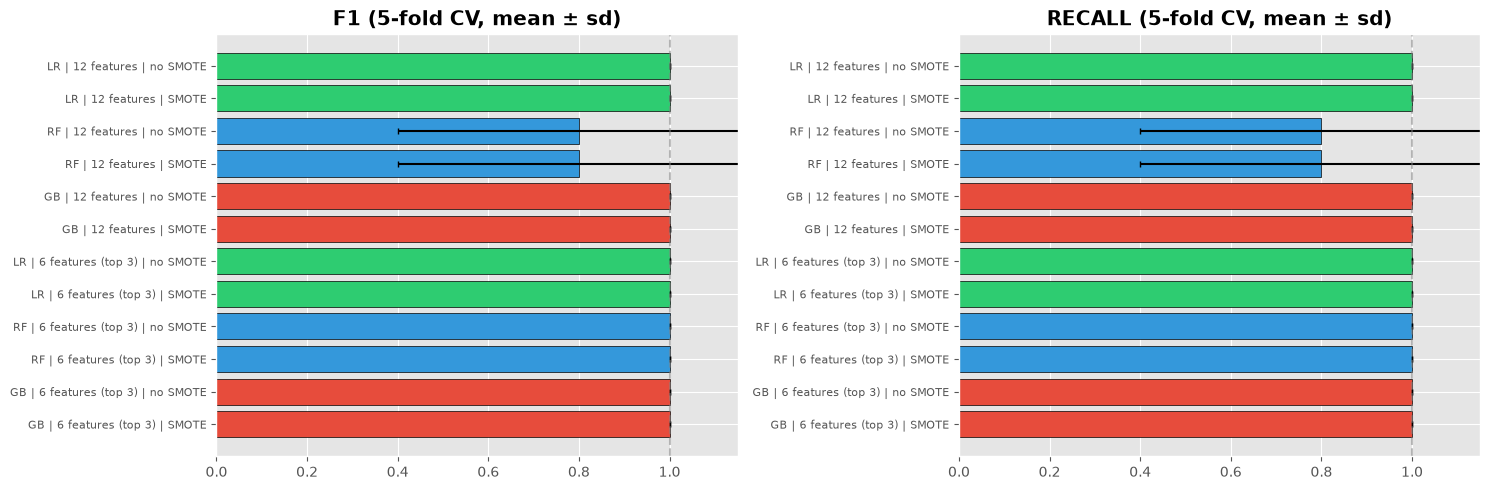

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
color_map = {'LR': '#2ecc71', 'RF': '#3498db', 'XGB': '#e74c3c', 'GB': '#e74c3c'}
labels_ = [r['config'] for r in results]
for ax, metric in zip(axes, ['f1', 'recall']):
    vals = [r[metric][0] for r in results]; errs = [r[metric][1] for r in results]
    ax.barh(range(len(labels_)), vals, xerr=errs, color=[color_map[l.split(' | ')[0]] for l in labels_],
            edgecolor='black', linewidth=0.5, capsize=2)
    ax.set_yticks(range(len(labels_))); ax.set_yticklabels(labels_, fontsize=8); ax.invert_yaxis()
    ax.set_xlim(0, 1.15); ax.axvline(1, color='gray', ls='--', alpha=.5)
    ax.set_title(f'{metric.upper()} (5-fold CV, mean ± sd)', fontweight='bold')
plt.tight_layout(); plt.show()

**Observations**
- LR is perfect with either feature set, with or without SMOTE. A low-capacity linear model suits 40 batches.
- RF on 12 features misses a rejected batch (F1 0.80): extra, uninformative sensors hurt tree models when there are only 5 positives.
- Every configuration reaches 1.0 on some folds, so a perfect CV score alone cannot rank them. The robustness checks in §5–§6 are what justify the design.
- SMOTE adds nothing for LR. We use **LR, 6 features, no SMOTE** (the simplest configuration). The LR uses no class weighting; the classes separate cleanly without it.

### Which features drive the classifier?

                      feature  coefficient  abs_coef
          aeration_rate_range       1.8707    1.8707
           aeration_rate_mean      -0.3201    0.3201
        feed_temperature_mean      -0.1677    0.1677
     fermentation_volume_mean       0.1523    0.1523
       feed_temperature_range      -0.1494    0.1494
  biomass_concentration_range      -0.1157    0.1157
        dissolved_oxygen_mean      -0.0775    0.0775
       dissolved_oxygen_range       0.0581    0.0581
 substrate_concentration_mean      -0.0505    0.0505
substrate_concentration_range      -0.0416    0.0416
   biomass_concentration_mean      -0.0404    0.0404
    fermentation_volume_range      -0.0318    0.0318


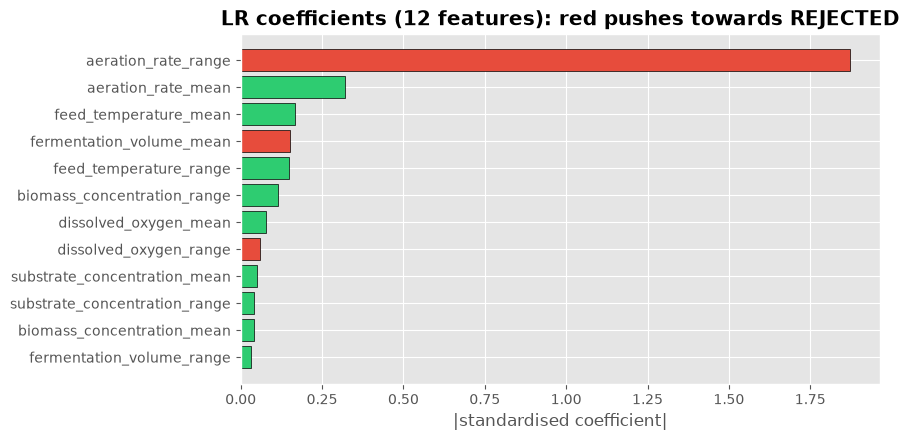

In [6]:
df_coef = pb.analyze_coefficients(df_calib, df_labels)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(df_coef.feature, df_coef.abs_coef, color=['#e74c3c' if c > 0 else '#2ecc71' for c in df_coef.coefficient],
        edgecolor='black', linewidth=.5)
ax.invert_yaxis(); ax.set_xlabel('|standardised coefficient|')
ax.set_title('LR coefficients (12 features): red pushes towards REJECTED', fontweight='bold')
plt.tight_layout(); plt.show()

`aeration_rate_range` dominates, so the classifier essentially asks *"was there an aeration excursion?"*. That is effective for the known fault, but **blind to anything else**: it reads only 3 of 20 sensors. Layer 2 closes that gap.

---
## 2. Layer 2: unsupervised MSPC monitor (multivariate statistical batch process model)

Classic batch MSPC, adapted to this data:

1. **Batch-wise unfolding:** each batch → 50 time bins × 20 sensors = 1000 variables.
2. **Set-point centring:** subtract each batch's own median per sensor. Accepted batches run at very different aeration set-points (4.8–8.1). Centring makes a *new but benign* set-point invisible, while dips, steps and drifts stay visible.
3. **Autoscaling with a robust variance floor:** no column's std may fall below 10 % of that sensor's overall spread. Without this, accepted batch **B_031** (whose on/off `feed_rate` switches slightly later than the others) produced an SPE about 600× the median and inflated the limits. That is a real example of benign, previously unseen variability.
4. **PCA** (90 % variance) on **accepted batches only**. **Hotelling T²** measures abnormal behaviour *within* the model; **SPE** (Q) measures behaviour the model has never seen.
5. **Control limits from leave-one-out** scores of the reference batches (honest new-batch behaviour): SPE via Box's g·χ² approximation, T² via the F distribution, both at 99 %.

In [7]:
mspc = pb.BatchMSPC().fit(df_calib[df_calib.batch_id.isin(acc_ids)])
print(f'Reference: {len(mspc.ref_ids)} accepted batches | PCs: {mspc.n_pc} | '
      f'T² limit: {mspc.t2_lim:.1f} | SPE limit: {mspc.spe_lim:.1f}')

sc_rej = mspc.score(df_calib[df_calib.batch_id.isin(rej_ids)])
sc_tst = mspc.score(df_test)
loo = pd.DataFrame({'batch_id': mspc.ref_ids, 'T2_ratio': mspc.loo_t2 / mspc.t2_lim, 'SPE_ratio': mspc.loo_spe / mspc.spe_lim})

loo_alarm = loo[(loo.T2_ratio > 1) | (loo.SPE_ratio > 1)]
print(f'\nCalibration ACCEPTED (leave-one-out): max T²/lim = {loo.T2_ratio.max():.2f}, max SPE/lim = {loo.SPE_ratio.max():.2f}, '
      f'alarms = {len(loo_alarm)}/35 {list(loo_alarm.batch_id)}')
print(f'Calibration REJECTED (never used for fitting): min SPE/lim = {sc_rej.SPE_ratio.min():.0f}x, alarms = {sc_rej.alarm.sum()}/5')
print(f'Test alarms: {sc_tst.alarm.sum()}  ->  {list(sc_tst.batch_id[sc_tst.alarm])}')
print(f'Largest non-alarm test batch: SPE/lim = {sc_tst[~sc_tst.alarm].SPE_ratio.max():.2f}, T²/lim = {sc_tst[~sc_tst.alarm].T2_ratio.max():.2f}')

Reference: 35 accepted batches | PCs: 7 | T² limit: 29.4 | SPE limit: 171.0

Calibration ACCEPTED (leave-one-out): max T²/lim = 0.60, max SPE/lim = 1.12, alarms = 1/35 ['B_031']
Calibration REJECTED (never used for fitting): min SPE/lim = 1089x, alarms = 5/5
Test alarms: 5  ->  ['B_008', 'B_041', 'B_052', 'B_060', 'B_064']
Largest non-alarm test batch: SPE/lim = 0.81, T²/lim = 0.75


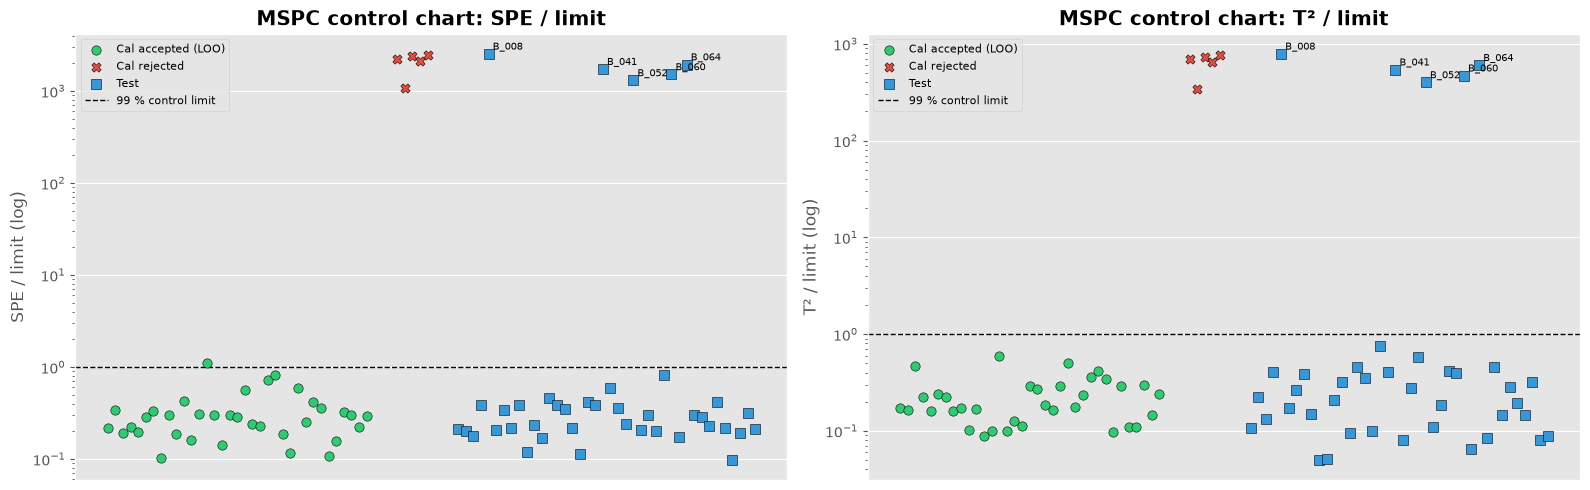

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, stat, name in [(axes[0], 'SPE_ratio', 'SPE / limit'), (axes[1], 'T2_ratio', 'T² / limit')]:
    groups = [('Cal accepted (LOO)', loo, '#2ecc71', 'o'), ('Cal rejected', sc_rej, '#e74c3c', 'X'),
              ('Test', sc_tst, '#3498db', 's')]
    x0 = 0
    for name_, d, c, m in groups:
        ax.scatter(range(x0, x0 + len(d)), d[stat], c=c, marker=m, s=45, edgecolors='k', lw=.4, label=name_, zorder=3)
        if name_ == 'Test':
            for i, (b, v) in enumerate(zip(d.batch_id, d[stat])):
                if v > 1: ax.annotate(b, (x0 + i, v), fontsize=7, xytext=(3, 3), textcoords='offset points')
        x0 += len(d) + 3
    ax.axhline(1, color='k', ls='--', lw=1, label='99 % control limit')
    ax.set_yscale('log'); ax.set_ylabel(name + ' (log)'); ax.set_xticks([])
    ax.set_title(f'MSPC control chart: {name}', fontweight='bold'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

The monitor never saw a rejected batch, yet **all 5 rejected calibration batches and exactly 5 test batches sit about three orders of magnitude (>1000×) above the limit**. 34 of 35 accepted batches stay below it in leave-one-out. The single excursion is B_031 at 1.1× (the late feed-switch batch), which is about what a 99 % limit should produce on 35 batches. The separation is not tuned: it comes from modelling *normal* operation only.

---
## 3. Contribution analysis: *why* did a batch alarm?

A classifier says *that* a batch is bad; contribution plots say *which sensor, when*. That is what an operator in the control room needs.

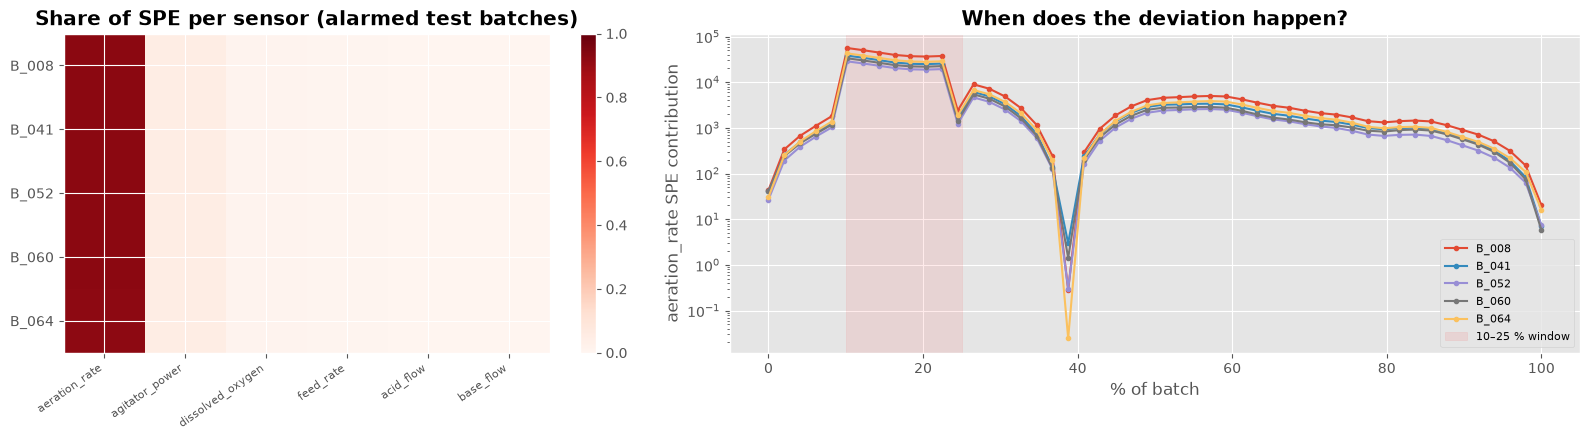

In [9]:
alarmed = sc_tst.loc[sc_tst.alarm, 'batch_id'].tolist()
contrib = mspc.contributions(df_test[df_test.batch_id.isin(alarmed)])
top = contrib.mean().sort_values(ascending=False).head(6).index

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={'width_ratios': [1, 1.4]})
im = axes[0].imshow(contrib[top].values, cmap='Reds', aspect='auto', vmin=0, vmax=1)
axes[0].set_xticks(range(len(top))); axes[0].set_xticklabels(top, rotation=35, ha='right', fontsize=8)
axes[0].set_yticks(range(len(contrib))); axes[0].set_yticklabels(contrib.index)
axes[0].set_title('Share of SPE per sensor (alarmed test batches)', fontweight='bold'); plt.colorbar(im, ax=axes[0])

for b in alarmed:
    ct = mspc.contribution_over_time(df_test[df_test.batch_id == b])['aeration_rate']
    axes[1].plot(np.linspace(0, 100, len(ct)), ct, marker='.', label=b)
axes[1].axvspan(10, 25, color='red', alpha=.08, label='10–25 % window')
axes[1].set_yscale('log'); axes[1].set_xlabel('% of batch'); axes[1].set_ylabel('aeration_rate SPE contribution')
axes[1].set_title('When does the deviation happen?', fontweight='bold'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

The diagnosis is the same fault as in calibration: `aeration_rate`, inside the 10–25 % window. That is independent confirmation of the classifier's decision, from a model that never saw a label.

---
## 4. Final predictions: combined strategy

In [10]:
tab, clf_pipe, clf_cols, _ = pb.predict_strategy(df_calib, df_labels, df_test)
show = tab.sort_values('SPE_ratio', ascending=False)[['batch_id', 'p_rejected', 'T2_ratio', 'SPE_ratio', 'label', 'reason']]
print(show.head(8).round(3).to_string(index=False))

df_submission = pb.predict_process_b()
print(f'\nClassifier-only and MSPC-only agree on every test batch: {(tab.clf_reject == tab.alarm).all()}')

MSPC: 7 PCs, T²-lim=29.4, SPE-lim=171.0
Decision counts: {'in control': 35, 'known fault (both layers)': 5}
batch_id  p_rejected  T2_ratio  SPE_ratio    label                    reason
   B_008       0.838   788.608   2533.620 rejected known fault (both layers)
   B_064       0.806   601.467   1938.474 rejected known fault (both layers)
   B_041       0.749   541.015   1727.737 rejected known fault (both layers)
   B_060       0.813   468.959   1514.313 rejected known fault (both layers)
   B_052       0.672   399.307   1303.183 rejected known fault (both layers)
   B_059       0.012     0.400      0.813 accepted                in control
   B_042       0.009     0.080      0.587 accepted                in control
   B_026       0.010     0.316      0.461 accepted                in control


MSPC: 7 PCs, T²-lim=29.4, SPE-lim=171.0
Decision counts: {'in control': 35, 'known fault (both layers)': 5}
[Process B] Test predictions: {'accepted': 35, 'rejected': 5}
[Process B] Rejected: B_008, B_041, B_052, B_060, B_064

Classifier-only and MSPC-only agree on every test batch: True


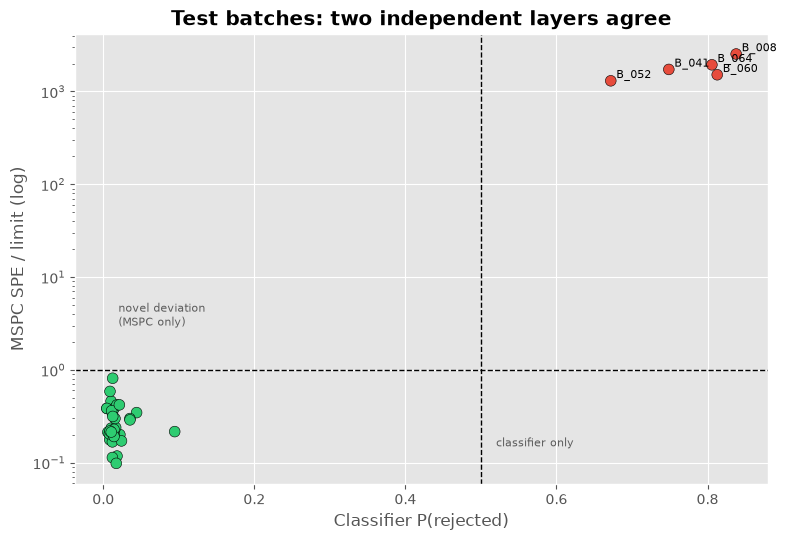

In [11]:
fig, ax = plt.subplots(figsize=(8, 5.5))
c = tab.label.map({'rejected': '#e74c3c', 'accepted': '#2ecc71'})
ax.scatter(tab.p_rejected, tab.SPE_ratio, c=c, s=60, edgecolors='k', lw=.4)
for _, r in tab[tab.label == 'rejected'].iterrows():
    ax.annotate(r.batch_id, (r.p_rejected, r.SPE_ratio), fontsize=8, xytext=(4, 2), textcoords='offset points')
ax.axvline(.5, ls='--', c='k', lw=1); ax.axhline(1, ls='--', c='k', lw=1)
ax.set_yscale('log'); ax.set_xlabel('Classifier P(rejected)'); ax.set_ylabel('MSPC SPE / limit (log)')
ax.text(.52, .15, 'classifier only', fontsize=8, alpha=.6); ax.text(.02, 3, 'novel deviation\n(MSPC only)', fontsize=8, alpha=.6)
ax.set_title('Test batches: two independent layers agree', fontweight='bold')
plt.tight_layout(); plt.show()

**Margins:** rejected test batches have P(rejected) 0.67–0.84 against at most 0.09 for any accepted one, and SPE ratios above 1300× against at most 0.81×. No test batch sits in an ambiguous zone, and the two layers, built on different data (labels vs accepted-only) and different features (3 vs 20 sensors), agree on all 40 batches.

---
## 5. Criterion: limited calibration set

How does performance hold up if far fewer batches had been available? We draw random small calibration subsets (100 repeats each), fit both layers, and score the **held-out** calibration batches. The MSPC uses only the accepted part of each subset.

 n_accepted  n_rejected  clf_F1_mean  clf_F1_p10  mspc_F1_mean  mspc_F1_p10  mspc_false_alarm_rate
          5           1        0.435         0.0         0.854        0.530                  0.073
          5           2        0.661         0.0         0.807        0.500                  0.075
         10           2        0.787         0.5         0.843        0.600                  0.061
         15           3        0.863         0.0         0.854        0.571                  0.050
         20           3        0.857         0.0         0.913        0.667                  0.036
         28           4        1.000         1.0         0.983        1.000                  0.013


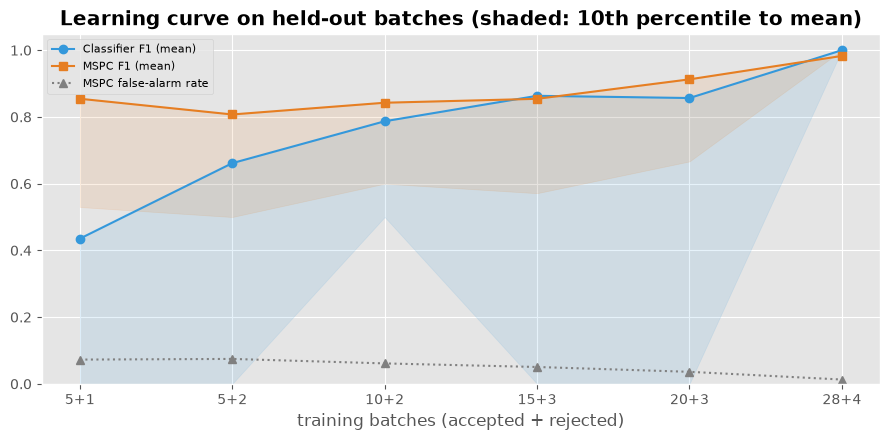

In [12]:
lc = pb.learning_curve(df_calib, df_labels, n_rep=100)
print(lc.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4.5))
xl = [f"{a}+{r}" for a, r in zip(lc.n_accepted, lc.n_rejected)]
ax.plot(xl, lc.clf_F1_mean, '-o', label='Classifier F1 (mean)', c='#3498db')
ax.fill_between(xl, lc.clf_F1_p10, lc.clf_F1_mean, color='#3498db', alpha=.12)
ax.plot(xl, lc.mspc_F1_mean, '-s', label='MSPC F1 (mean)', c='#e67e22')
ax.fill_between(xl, lc.mspc_F1_p10, lc.mspc_F1_mean, color='#e67e22', alpha=.12)
ax.plot(xl, lc.mspc_false_alarm_rate, ':^', label='MSPC false-alarm rate', c='gray')
ax.set_xlabel('training batches (accepted + rejected)'); ax.set_ylim(0, 1.05)
ax.set_title('Learning curve on held-out batches (shaded: 10th percentile to mean)', fontweight='bold'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

- With very few batches the **MSPC is far more reliable than the classifier**. It needs no rejected examples, so it does not depend on which fault happened to be in the calibration set.
- The classifier needs about 4 rejected batches before it becomes stable (10th-percentile F1 = 1.0).
- The MSPC's price for small data is a higher false-alarm rate. §7 shows how self-training brings it down without new labels.

---
## 6. Criteria: independent variables, unseen variability, discrimination

### 6a. Leave-one-rejected-out: a fault type the classifier has not seen
Retrain the classifier without one rejected batch, then score that batch. The MSPC never sees rejected batches anyway.

In [13]:
loro = pb.leave_one_rejected_out(df_calib, df_labels)
print(loro.round(3).to_string(index=False))

held_out  clf_p_rejected  mspc_SPE_ratio  mspc_alarm
   B_017           0.888        2240.374        True
   B_032           0.541        1089.241        True
   B_049           0.802        2379.896        True
   B_075           0.779        2104.999        True
   B_078           0.902        2481.407        True


Without B_032 in training, the classifier scores it at only about 0.54, barely above the 0.5 threshold, because its set-point is unlike that of the other rejects. The MSPC flags it at more than 1000× the limit. This is why the classifier is never used alone.

### 6b. Synthetic disturbances on held-out accepted batches
Each accepted batch is held out of **both** layers and disturbed, then scored (35 batches per scenario).
- **Benign** scenarios should *not* alarm: none, a set-point shift (aeration −30 % for the whole batch), extra sensor noise.
- **Fault** scenarios should alarm: a step in the 10–25 % window on the dip sensor and on sensors the classifier never reads.

Step sizes are relative to each sensor's typical level.

In [14]:
scenarios = [
    # benign / unseen-but-acceptable variability
    ('aeration_rate', 'none', 0.0), ('aeration_rate', 'level', -0.30), ('aeration_rate', 'noise', 0.005),
    ('dissolved_oxygen', 'noise', 0.01),
    # faults
    ('aeration_rate', 'step', -0.20), ('ph', 'step', 0.05), ('reactor_temperature', 'step', 0.01),
    ('agitator_power', 'step', 0.05), ('dissolved_oxygen', 'step', 0.20),
    ('biomass_concentration', 'step', 0.20), ('substrate_concentration', 'step', 0.50),
]
dist = pb.disturbance_test(df_calib, df_labels, scenarios)
dist.insert(0, 'type', ['benign'] * 4 + ['fault'] * 7)
print(dist.to_string(index=False))

  type                  sensor  kind   size classifier_flagged mspc_flagged
benign           aeration_rate  none  0.000               0/35         0/35
benign           aeration_rate level -0.300               0/35         0/35
benign           aeration_rate noise  0.005               0/35         0/35
benign        dissolved_oxygen noise  0.010               0/35         0/35
 fault           aeration_rate  step -0.200              16/35        35/35
 fault                      ph  step  0.050               0/35        35/35
 fault     reactor_temperature  step  0.010               0/35        33/35
 fault          agitator_power  step  0.050               0/35        35/35
 fault        dissolved_oxygen  step  0.200               0/35        35/35
 fault   biomass_concentration  step  0.200               0/35         3/35
 fault substrate_concentration  step  0.500               0/35         0/35


**Reading the table**
- **Benign variability (unseen set-point, extra noise) causes no false alarms in either layer.** Set-point centring and the variance floor do their job.
- Faults on **pH, reactor temperature, agitator power and dissolved oxygen** are caught by the MSPC almost every time; the classifier catches **none** of them. This is the "several independent variables" criterion: with weakly correlated sensors, a model has to watch each of them, not just the one that mattered in calibration.
- Even on the known fault sensor, a smaller dip (−20 %) slips past the classifier in more than half of the batches, but never past the MSPC.
- **Known limitation:** steps in `biomass_concentration` and `substrate_concentration` are hard to detect. These are slow, highly variable process states (they differ a lot between normal batches), so a step of this size sits inside normal variation. Monitoring them would need trajectory alignment or derived rates, which is a natural next step.

---
## 7. Criterion: recalibration / self-supervised learning

New batches arrive without lab labels. The update loop:
1. Score them with both layers.
2. **Pseudo-label** only confident cases:
   - *accepted* if classifier P < 0.05 **and** both MSPC statistics are < 5× the limit. A mild excursion on a model built from few batches is usually un-modelled normal variability; real faults sit hundreds of times above the limit.
   - *rejected* if classifier P > 0.5 **and** an MSPC alarm (the two layers agree).
   - everything else goes to **human review** (not pseudo-labelled).
3. Add the pseudo-labelled batches to the reference set and **refit both layers and the control limits**.
4. Repeat.

### 7a. Applied to the real test batches

In [15]:
cal_u, lab_u, hist = pb.self_training_update(df_calib, df_labels, df_test, rounds=1)
tab_u, *_ = pb.predict_strategy(cal_u, lab_u, df_test, verbose=False)
changed = (tab_u.set_index('batch_id').label != tab.set_index('batch_id').label).sum()
print(f'\nPseudo-labelled: {len(lab_u) - len(df_labels)} test batches '
      f"({(lab_u.label == 'rejected').sum() - len(rej_ids)} rejected)")
print(f'Predictions changed after recalibration: {changed}/40')

 round  n_accepted_ref  n_rejected_ref  n_PCs  T2_lim  SPE_lim
     0              35               5      7   29.36   170.99
     1              69              10      7   22.92   117.22



Pseudo-labelled: 39 test batches (5 rejected)
Predictions changed after recalibration: 0/40


39 of 40 test batches are confidently pseudo-labelled (34 accepted + the 5 rejected, on which both layers agree). One batch stays unlabelled for review because its classifier probability falls between the two cut-offs. The reference set grows from 40 to 79 batches, and with twice as many normal batches the **control limits tighten** (T² about 29 → 23, SPE about 171 → 117), so smaller faults become detectable. The final predictions are **stable**: recalibration flips no decision.

### 7b. Does self-training help when the calibration set is small?
Simulation: start from only **10 accepted + 2 rejected** labelled batches, self-train (2 rounds) on the unlabelled test batches, and evaluate on the held-out labelled calibration batches. 30 random repeats.

                       before  after self-training
Classifier F1           0.743                0.960
MSPC recall             1.000                1.000
MSPC false-alarm rate   0.095                0.033
Combined F1             0.799                0.895

Avg pseudo-labelled batches: 33.1 (of which rejected: 4.6)


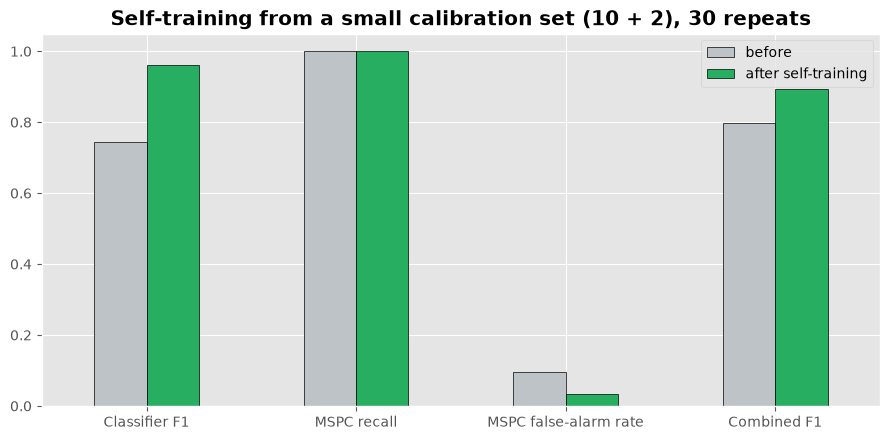

In [16]:
stb = pb.self_training_benefit(df_calib, df_labels, df_test, n_acc=10, n_rej=2, n_rep=30)
summary = pd.DataFrame({
    'before': [stb.clf_F1_before.mean(), stb.mspc_recall_before.mean(), stb.mspc_false_alarm_before.mean(), stb.combined_F1_before.mean()],
    'after self-training': [stb.clf_F1_after.mean(), stb.mspc_recall_after.mean(), stb.mspc_false_alarm_after.mean(), stb.combined_F1_after.mean()],
}, index=['Classifier F1', 'MSPC recall', 'MSPC false-alarm rate', 'Combined F1'])
print(summary.round(3).to_string())
print(f'\nAvg pseudo-labelled batches: {stb.n_pseudo_labelled.mean():.1f} (of which rejected: {stb.pseudo_rejected.mean():.1f})')

ax = summary.plot.bar(figsize=(9, 4.5), color=['#bdc3c7', '#27ae60'], edgecolor='k', rot=0)
ax.set_ylim(0, 1.05); ax.set_title('Self-training from a small calibration set (10 + 2), 30 repeats', fontweight='bold')
plt.tight_layout(); plt.show()

Without any new lab labels, self-training raises the classifier's F1, cuts the MSPC false-alarm rate by about two-thirds, and keeps MSPC recall at 100 %. The combined strategy recovers most of the performance of the full 40-batch calibration set from 12 labelled batches.

**Safeguards in production:** pseudo-label only when the layers agree; route disagreements and "novel deviation" alarms to a human (active learning); keep the original labelled set fixed and track the control limits over time to detect drift.

---
## 8. Summary

| Criterion | Approach | Evidence (this notebook) |
|---|---|---|
| **Limited calibration set** | Low-capacity LR (6 features); MSPC needs accepted batches only | §5: with 5 accepted batches the MSPC reaches far higher F1 than the classifier |
| **Low correlation, several independent variables** | MSPC on all 20 sensors | §6b: pH / temperature / agitator / DO faults caught by the MSPC, missed by the classifier |
| **Unseen process variability** | Set-point centring, robust variance floor (B_031 case), LOO control limits | §6b: zero false alarms for set-point shifts and noise; §6a: unseen-fault proxy (B_032) still alarmed |
| **Discriminating acceptable vs unacceptable** | Two independent layers + contribution diagnosis | §2–§4: 5/5 rejected flagged at >1000× the limit, 34/35 accepted below 1× (LOO); layers agree on all 40 test batches |
| **Recalibration / self-supervised learning** | Confident pseudo-labelling, refit of models and limits | §7: predictions stable on real data; from 10+2 batches, F1 up and false alarms down without new labels |

**Final Process B prediction:** B_008, B_041, B_052, B_060, B_064 rejected; the other 35 accepted.

**Limitations / next steps:** slow process states (biomass, substrate) need trajectory alignment to be monitored sensitively; control limits are estimated from 35 batches, so their tails are uncertain; pseudo-labelling should run with human review of borderline cases.